- best_CNN_LSTM_solar_original_2-50-2.pth - файл с оригинальным повторением опыта со входом 2, 50 скрытым, 2 выход
- best_CNN_LSTM_solar_newq2.pth - файл с измененной структурой для файла lab41.ipynb со скрытым слоем в 100, входом в 20, со слоем conv, SmoothL1Loss и AdamW
- best_CNN_LSTM_solar_2.pth - файл с измененной структурой для файла lab41.ipynb со скрытым слоем в 100, входом в 20, со слоем conv и GELU, с self.norm = nn.LayerNorm(hidden_size), SmoothL1Loss и AdamW
- best_CNN_LSTM_solar_18_18-100-2.pth и best_CNN_LSTM_solar_20features.pth где на вход поддаются либо 18, либо 20 признаков из всего датасета

In [8]:
import os
import copy
import matplotlib.dates as mdates

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DATA_PATH = "kpdata1.csv"

COLUMNS = (
    ["year", "month", "day", "days", "days_m", "Bsr", "dB"]
    + [f"Kp{i}" for i in range(1, 9)]
    + [f"ap{i}" for i in range(1, 9)]
    + ["Ap", "SN", "F107obs", "F107adj", "D"]
)

WINDOW_IN = 135
WINDOW_OUT = 27

BATCH_SIZE = 32
NUM_EPOCHS = 300
LEARNING_RATE = 0.0001
PATIENCE = 25

TARGET_COLUMNS = ["SN", "F107obs"]
FEATURE_COLUMNS = (
    TARGET_COLUMNS
    + [f"Kp{i}" for i in range(1, 9)]
    + [f"ap{i}" for i in range(1, 9)]
    + ["Ap", "F107adj"]
)
INPUT_SIZE = len(FEATURE_COLUMNS)
# INPUT_SIZE = 2

MIN_VALUES = np.array([0.0, 64.6], dtype=np.float32)
AMPLITUDES = np.array([428.0, 367.0], dtype=np.float32)

# даты прогнозирования как из статьи 
HORIZONS = [1, 4, 20]

MODEL_PATH = (
    f"best_CNN_LSTM_solar_20features.pth"
)

In [7]:
class CNNLSTM(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size=100,
        output_size=2,
        window_out=WINDOW_OUT
    ):
        super(CNNLSTM, self).__init__()

        self.window_out = window_out

        self.lstm_1 = nn.LSTM(
            input_size,
            hidden_size,
            batch_first=True
        )

        self.batch_norm_output = nn.BatchNorm1d(hidden_size)
        self.batch_norm_h = nn.BatchNorm1d(hidden_size)
        self.batch_norm_c = nn.BatchNorm1d(hidden_size)

        self.lstm_2 = nn.LSTM(
            hidden_size,
            hidden_size,
            batch_first=True
        )

        self.lin = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):
        lstm_output, (h, c) = self.lstm_1(x)

        output = lstm_output[:, -1, :]

        output = self.batch_norm_output(output)
        h = self.batch_norm_h(h[-1])
        c = self.batch_norm_c(c[-1])

        decoder_input = output.unsqueeze(1).repeat(
            1,
            self.window_out,
            1
        )

        decoder_output, _ = self.lstm_2(
            decoder_input,
            (
                h.unsqueeze(0),
                c.unsqueeze(0)
            )
        )

        output = self.lin(decoder_output)

        return output

In [9]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    header=None,
    names=COLUMNS
)

df["date"] = pd.to_datetime(
    df[["year", "month", "day"]]
)

df.loc[df["F107obs"] == -1, "F107obs"] = np.nan
df.loc[df["F107adj"] == -1, "F107adj"] = np.nan

kp_columns = [f"Kp{i}" for i in range(1, 9)]
ap_columns = [f"ap{i}" for i in range(1, 9)]

for col in kp_columns + ap_columns + ["Ap"]:
    df.loc[df[col] < 0, col] = np.nan

df[FEATURE_COLUMNS] = df[FEATURE_COLUMNS].interpolate(
    method="linear",
    limit_direction="both"
)
df[FEATURE_COLUMNS] = df[FEATURE_COLUMNS].ffill().bfill()
features = df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
values = df[TARGET_COLUMNS].to_numpy(dtype=np.float32)
dates = pd.to_datetime(df["date"]).reset_index(drop=True)
test_start = dates.searchsorted(
    pd.Timestamp("2020-01-01")
)

val_start = int(test_start * (1 - 0.20))
scaler = StandardScaler()

scaler.fit(features[:val_start])

features_norm = scaler.transform(
    features
).astype(np.float32)

values_norm = (
    values - MIN_VALUES
) / AMPLITUDES

def make_windows(data, targets, starts):
    X = np.array([
        data[i - WINDOW_IN:i]
        for i in starts
    ], dtype=np.float32)

    y = np.array([
        targets[i:i + WINDOW_OUT]
        for i in starts
    ], dtype=np.float32)

    return X, y


train_starts = np.arange(
    WINDOW_IN,
    val_start - WINDOW_OUT + 1
)

val_starts = np.arange(
    val_start,
    test_start - WINDOW_OUT + 1,
    WINDOW_OUT
)

X_train, y_train = make_windows(
    features_norm,
    values_norm,
    train_starts
)

X_val, y_val = make_windows(
    features_norm,
    values_norm,
    val_starts
)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val),
        torch.tensor(y_val)
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (17078, 135, 20)
y_train: (17078, 27, 2)
X_val: (159, 135, 20)
y_val: (159, 27, 2)


In [10]:
model = CNNLSTM(
    input_size=INPUT_SIZE,
    output_size=len(TARGET_COLUMNS),
    window_out=WINDOW_OUT
)

if os.path.exists(MODEL_PATH):

    checkpoint = torch.load(
        MODEL_PATH,
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    history = checkpoint["history"]
else:
    loss_function = nn.L1Loss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(NUM_EPOCHS):
        model.train()

        train_loss = 0.0
        train_count = 0

        for x_batch, y_batch in train_loader:
            prediction = model(x_batch)

            loss = loss_function(
                prediction,
                y_batch
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(x_batch)
            train_count += len(x_batch)

        train_loss /= train_count

        model.eval()

        val_loss = 0.0
        val_count = 0

        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                prediction = model(x_batch)

                loss = loss_function(
                    prediction,
                    y_batch
                )

                val_loss += loss.item() * len(x_batch)
                val_count += len(x_batch)

        val_loss /= val_count

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    best_epoch = np.argmin(history["val_loss"]) + 1
    model.load_state_dict(best_state)

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "history": history
        },
        MODEL_PATH
    )

model.eval()

CNNLSTM(
  (lstm_1): LSTM(20, 100, batch_first=True)
  (batch_norm_output): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batch_norm_h): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batch_norm_c): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (lstm_2): LSTM(100, 100, batch_first=True)
  (lin): Linear(in_features=100, out_features=2, bias=True)
)

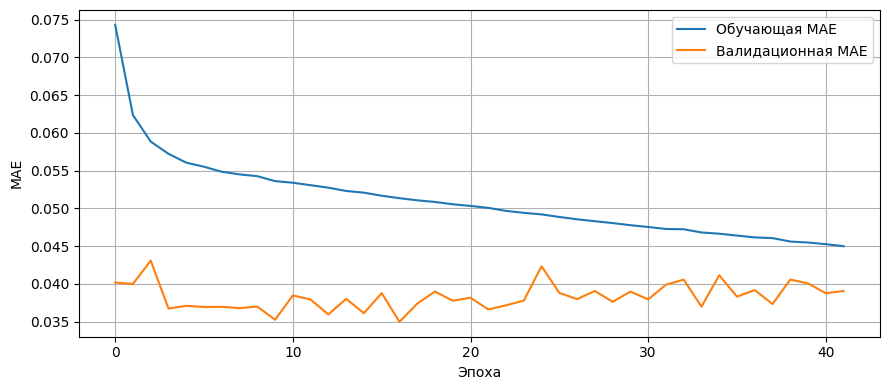

In [11]:
plt.figure(figsize=(9, 4))

plt.plot(
    history["train_loss"],
    label="Обучающая MAE"
)

plt.plot(
    history["val_loss"],
    label="Валидационная MAE"
)

plt.xlabel("Эпоха")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [12]:
class MetricsCalculator:
    def calculate_comprehensive_metrics(self, y_true, y_pred, model_name=""):
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        denominator = (np.abs(y_true) + np.abs(y_pred) + 1e-10)
        mape = np.mean(2 * np.abs(y_true - y_pred) / denominator) * 100
        print(f"\n{model_name} - МЕТРИКИ КАЧЕСТВА:")
        print("-" * 40)
        print(f"MSE:  {mse:.6f}")
        print(f"RMSE: {rmse:.6f}")
        print(f"MAE:  {mae:.6f}")
        print(f"R²:   {r2:.6f}")
        print(f"MAPE: {mape:.4f}%")
        return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}

    def approximation_quality(self, deviation, y_pred, y_true):
        y_pred = np.array(y_pred).flatten()
        y_true = np.array(y_true).flatten()
        if len(y_pred) != len(y_true):
            print(f"ОШИБКА: Разные размеры y_pred({len(y_pred)}) и y_true({len(y_true)})")
            return 0
        absolute_errors = np.abs(y_pred - y_true)
        within_deviation = np.sum(absolute_errors <= deviation)
        percentage = (within_deviation / len(y_true)) * 100
        return min(percentage, 100.0)

In [13]:
def inverse_normalize(x):
    return x * AMPLITUDES + MIN_VALUES

test_rows = []
model.eval()

def f():
    with torch.no_grad():
        for start in range(
            test_start,
            len(values_norm),
            WINDOW_OUT
        ):

            if (INPUT_SIZE ==2):
                x = torch.tensor(
                    values_norm[start - WINDOW_IN:start]
                ).unsqueeze(0)
            else:
                x = torch.tensor(
                    features_norm[start - WINDOW_IN:start]
                ).unsqueeze(0)

            prediction = model(x).numpy()[0]

            count = min(
                WINDOW_OUT,
                len(values_norm) - start
            )

            prediction = inverse_normalize(
                prediction[:count]
            )

            actual = inverse_normalize(
                values_norm[start:start + count]
            )

            for i in range(count):
                test_rows.append({
                    "date": dates.iloc[start + i],

                    "SN_actual": actual[i, 0],
                    "SN_pred": prediction[i, 0],

                    "F107obs_actual": actual[i, 1],
                    "F107obs_pred": prediction[i, 1]
                })

f()

test_predictions = pd.DataFrame(test_rows)

In [14]:
metrics_calculator = MetricsCalculator()

metrics = metrics_calculator.calculate_comprehensive_metrics(
    y_true=test_predictions["SN_actual"],
    y_pred=test_predictions["SN_pred"],
    model_name="CNN-SN",
)

deviation_sn = 0.1 * np.std(test_predictions["SN_actual"])

quality_sn = metrics_calculator.approximation_quality(
    deviation=deviation_sn,
    y_pred=test_predictions["SN_pred"],
    y_true=test_predictions["SN_actual"]
)

print(f"Качество аппроксимации SN: {quality_sn:.2f}%")

metrics = metrics_calculator.calculate_comprehensive_metrics(
    y_true=test_predictions["F107obs_actual"],

    y_pred=test_predictions["F107obs_pred"],

    model_name="CNN-F107",
)

deviation_f107 = 0.1 * np.std(test_predictions["F107obs_actual"])

quality_f107 = metrics_calculator.approximation_quality(
    deviation=deviation_f107,
    y_pred=test_predictions["F107obs_pred"],
    y_true=test_predictions["F107obs_actual"]
)

print(f"Качество аппроксимации F10.7: {quality_f107:.2f}%")


CNN-SN - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  700.982910
RMSE: 26.476082
MAE:  18.050409
R²:   0.662666
MAPE: 79.6026%
Качество аппроксимации SN: 22.49%

CNN-F107 - МЕТРИКИ КАЧЕСТВА:
----------------------------------------
MSE:  334.907715
RMSE: 18.300484
MAE:  10.435978
R²:   0.710118
MAPE: 9.2864%
Качество аппроксимации F10.7: 42.47%


Используем оценку на непересекающихся окнах (non-overlapping windows) с прямым многошаговым прогнозом

In [26]:
def inverse_normalize(x):
    return x * AMPLITUDES + MIN_VALUES

test_rows = []
model.eval()

with torch.no_grad():
    for start in range(test_start, len(values_norm) - WINDOW_OUT + 1, WINDOW_OUT):
        x = torch.tensor(
            features_norm[start - WINDOW_IN:start],
            dtype=torch.float32
        ).unsqueeze(0)

        prediction = model(x).numpy()[0] 

        count = min(WINDOW_OUT, len(values_norm) - start)
        pred = inverse_normalize(prediction[:count])
        actual = inverse_normalize(values_norm[start:start + count])

        for i in range(count):
            test_rows.append({
                "date": dates.iloc[start + i],
                "horizon": i + 1,         
                "SN_actual": actual[i, 0],
                "SN_pred": pred[i, 0],
                "F107obs_actual": actual[i, 1],
                "F107obs_pred": pred[i, 1],
            })

test_predictions = pd.DataFrame(test_rows)
print(test_predictions)

           date  horizon   SN_actual     SN_pred  F107obs_actual  F107obs_pred
0    2020-01-01        1    6.000000    5.263971       71.800003     68.911621
1    2020-01-02        2   12.000000    3.923546       71.900002     70.491409
2    2020-01-03        3   13.000000    4.039732       71.199997     70.722580
3    2020-01-04        4   12.000000    3.830960       72.199997     70.737106
4    2020-01-05        5   14.000000    4.091494       71.800003     71.022377
...         ...      ...         ...         ...             ...           ...
1129 2023-02-03       23   63.999996  119.845497      134.500000    138.592758
1130 2023-02-04       24   71.000000  120.271057      139.000000    138.887848
1131 2023-02-05       25   74.000000  120.635086      144.000000    139.140549
1132 2023-02-06       26  111.000000  120.946457      156.699997    139.356674
1133 2023-02-07       27  107.000000  121.212822      184.699997    139.541397

[1134 rows x 6 columns]


Skill Score (индекс качества прогноза), посчитанный по метрике MAE относительно инерционного (персистентного) бейзлайна. 

In [27]:
def skill_score(y_true, y_pred, y_base):
    mae_m = mean_absolute_error(y_true, y_pred)
    mae_b = mean_absolute_error(y_true, y_base)
    return 1.0 - mae_m / (mae_b + 1e-12), mae_m, mae_b

rows_skill = []
model.eval()

with torch.no_grad():
    for start in range(test_start, len(values_norm) - WINDOW_OUT + 1, WINDOW_OUT):
        x = torch.tensor(
            features_norm[start - WINDOW_IN:start],
            dtype=torch.float32
        ).unsqueeze(0)
        pred = inverse_normalize(model(x).numpy()[0])  
        actual = inverse_normalize(values_norm[start:start + WINDOW_OUT])
        last = inverse_normalize(values_norm[start - 1])  

        for h in [1, 4, 20]:
            rows_skill.append({
                "horizon": h,
                "SN_true": actual[h - 1, 0],
                "SN_pred": pred[h - 1, 0],
                "SN_base": last[0],
                "F_true": actual[h - 1, 1],
                "F_pred": pred[h - 1, 1],
                "F_base": last[1],
            })

df_s = pd.DataFrame(rows_skill)

for h in [1, 4, 20]:
    m = df_s["horizon"] == h
    sk_sn, mae_m, mae_b = skill_score(
        df_s.loc[m, "SN_true"], df_s.loc[m, "SN_pred"], df_s.loc[m, "SN_base"]
    )
    sk_f, mae_mf, mae_bf = skill_score(
        df_s.loc[m, "F_true"], df_s.loc[m, "F_pred"], df_s.loc[m, "F_base"]
    )
    print(f"h={h}: SN skill={sk_sn:.3f} (MAE model={mae_m:.2f}, base={mae_b:.2f})")
    print(f"h={h}: F10.7 skill={sk_f:.3f} (MAE model={mae_mf:.2f}, base={mae_bf:.2f})")

h=1: SN skill=-0.017 (MAE model=7.94, base=7.81)
h=1: F10.7 skill=-0.480 (MAE model=4.26, base=2.88)
h=4: SN skill=0.253 (MAE model=13.13, base=17.57)
h=4: F10.7 skill=0.148 (MAE model=7.63, base=8.96)
h=20: SN skill=0.170 (MAE model=19.75, base=23.79)
h=20: F10.7 skill=0.100 (MAE model=10.15, base=11.28)


# Результаты работы модели на тестовом ряду значений числа солнечных пятен

In [15]:
predictions = {
    h: np.full(
        (len(values_norm), len(TARGET_COLUMNS)),
        np.nan
    )
    for h in HORIZONS
}

model.eval()

with torch.no_grad():
    for start in range(test_start, len(values_norm) - max(HORIZONS) + 1):
        x = torch.tensor(
            features_norm[start-WINDOW_IN:start],
            dtype=torch.float32
        ).unsqueeze(0)

        if(INPUT_SIZE==2):
            x = torch.tensor(
                values_norm[start-WINDOW_IN:start],
                dtype=torch.float32
            ).unsqueeze(0)

        prediction = model(x).cpu().numpy()[0]
        prediction = inverse_normalize(prediction)

        for h in HORIZONS:
            predictions[h][start+h-1] = prediction[h-1]

In [16]:
test_predictions_horizons = pd.DataFrame({
    "date": dates.iloc[test_start:].to_numpy(),

    "SN_actual": inverse_normalize(
        values_norm[test_start:]
    )[:, 0],

    "F107obs_actual": inverse_normalize(
        values_norm[test_start:]
    )[:, 1],

    "SN_pred_1": predictions[1][test_start:, 0],
    "SN_pred_4": predictions[4][test_start:, 0],
    "SN_pred_20": predictions[20][test_start:, 0],

    "F107_pred_1": predictions[1][test_start:, 1],
    "F107_pred_4": predictions[4][test_start:, 1],
    "F107_pred_20": predictions[20][test_start:, 1]
})

plot_start = pd.Timestamp("2020-10-01")
plot_end = pd.Timestamp("2022-10-31")

plot_data = test_predictions_horizons[
    (test_predictions_horizons["date"] >= plot_start) &
    (test_predictions_horizons["date"] <= plot_end)
].copy()

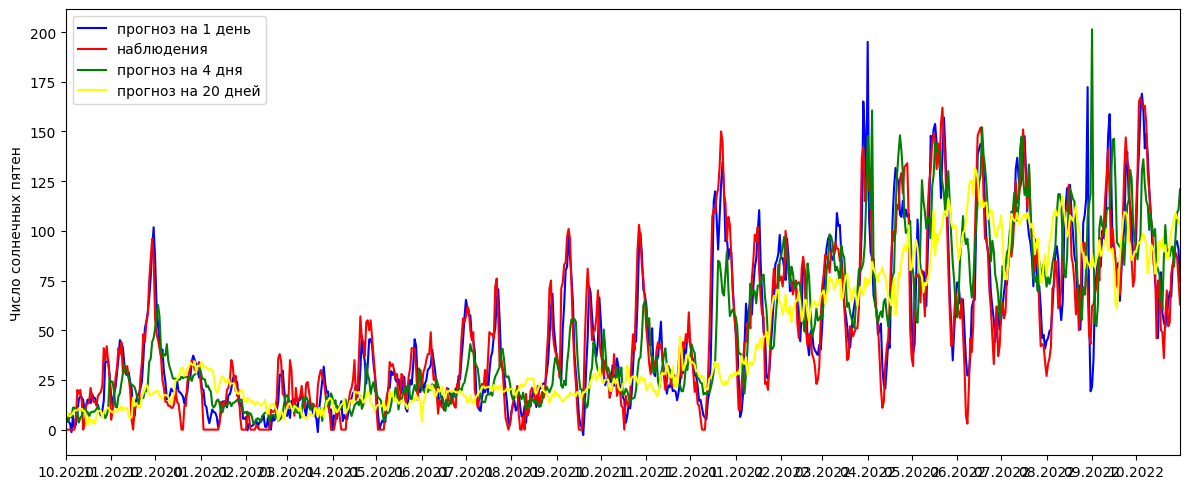

In [29]:
from matplotlib.ticker import FuncFormatter

def date_formatter(x, pos):
    date = mdates.num2date(x)
    return date.strftime("%m.%Y")

def date_formatter(x, pos):
    date = mdates.num2date(x)
    return date.strftime("%m.%Y")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    plot_data["date"],
    plot_data["SN_pred_1"],
    color="blue",
    label="прогноз на 1 день"
)

ax.plot(
    plot_data["date"],
    plot_data["SN_actual"],
    color="red",
    label="наблюдения"
)

ax.plot(
    plot_data["date"],
    plot_data["SN_pred_4"],
    color="green",
    label="прогноз на 4 дня"
)

ax.plot(
    plot_data["date"],
    plot_data["SN_pred_20"],
    color="yellow",
    label="прогноз на 20 дней"
)

ax.set_xlim(plot_start, plot_end)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

ax.xaxis.set_major_formatter(
    FuncFormatter(date_formatter)
)

ax.set_ylabel("Число солнечных пятен")
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()


Результаты работы модели на тестовом ряду значений потока радиоизлучения на 10,4 см

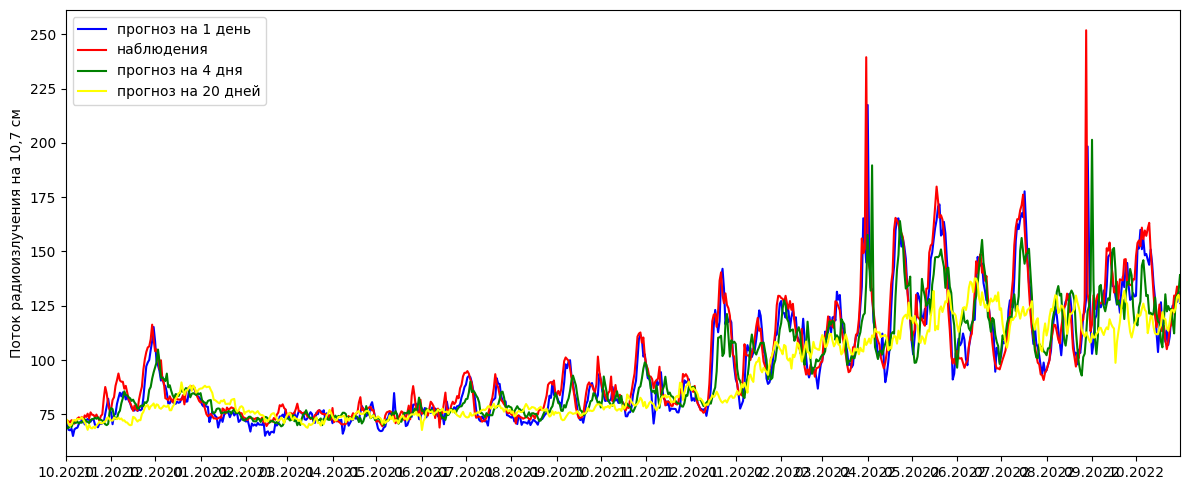

In [30]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    plot_data["date"],
    plot_data["F107_pred_1"],
    color="blue",
    label="прогноз на 1 день"
)

ax.plot(
    plot_data["date"],
    plot_data["F107obs_actual"],
    color="red",
    label="наблюдения"
)

ax.plot(
    plot_data["date"],
    plot_data["F107_pred_4"],
    color="green",
    label="прогноз на 4 дня"
)

ax.plot(
    plot_data["date"],
    plot_data["F107_pred_20"],
    color="yellow",
    label="прогноз на 20 дней"
)

ax.set_xlim(plot_start, plot_end)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

ax.xaxis.set_major_formatter(
    FuncFormatter(date_formatter)
)

ax.set_ylabel("Поток радиоизлучения на 10,7 см")
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()


Результаты прогноза модели на солнечные сутки (27 дней) c 25.10.2022 по 20.11.2022: число
солнечных пятен

In [32]:
forecast_start_date = pd.Timestamp("2022-10-25")
forecast_start = dates.searchsorted(forecast_start_date)

assert dates.iloc[forecast_start] == forecast_start_date


forecast_end = forecast_start + WINDOW_OUT
forecast_dates = dates.iloc[forecast_start:forecast_end]

x_forecast = torch.tensor(
    features_norm[forecast_start-WINDOW_IN:forecast_start],
    dtype=torch.float32
).unsqueeze(0)

if(INPUT_SIZE==2):
    x_forecast = torch.tensor(
        values_norm[forecast_start-WINDOW_IN:forecast_start],
        dtype=torch.float32
    ).unsqueeze(0)

model.eval()

with torch.no_grad():
    forecast = model(x_forecast).cpu().numpy()[0]

forecast = inverse_normalize(forecast)

actual = inverse_normalize(
    values_norm[forecast_start:forecast_end]
)

print("Начало прогноза:", forecast_dates.iloc[0])
print("Конец прогноза:", forecast_dates.iloc[-1])
print("Количество дней:", len(forecast_dates))

Начало прогноза: 2022-10-25 00:00:00
Конец прогноза: 2022-11-20 00:00:00
Количество дней: 27


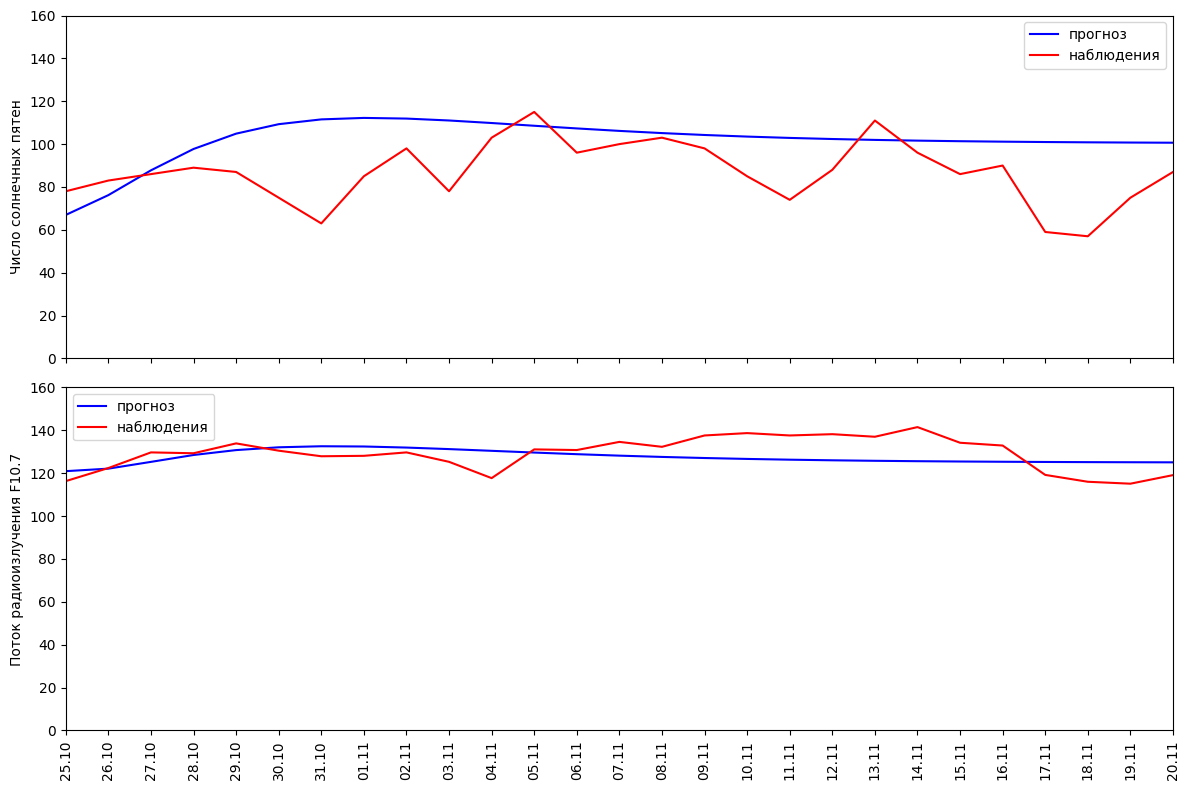

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# число солнечных пятен
axes[0].plot(
    forecast_dates,
    forecast[:, 0],
    color="blue",
    label="прогноз"
)

axes[0].plot(
    forecast_dates,
    actual[:, 0],
    color="red",
    label="наблюдения"
)

axes[0].set_ylim(0, 160)
axes[0].set_yticks(range(0, 161, 20))
axes[0].set_ylabel("Число солнечных пятен")
axes[0].legend(loc="upper right")


# поток радиоизлучения F10.7
axes[1].plot(
    forecast_dates,
    forecast[:, 1],
    color="blue",
    label="прогноз"
)

axes[1].plot(
    forecast_dates,
    actual[:, 1],
    color="red",
    label="наблюдения"
)

axes[1].set_ylim(0, 160)
axes[1].set_yticks(range(0, 161, 20))
axes[1].set_ylabel("Поток радиоизлучения F10.7")
axes[1].legend(loc="upper left")


# Настройка дат
axes[1].xaxis.set_major_locator(
    mdates.DayLocator(interval=1)
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d.%m")
)

axes[1].tick_params(axis="x", rotation=90)

axes[0].set_xlim(
    forecast_dates.iloc[0],
    forecast_dates.iloc[-1]
)

fig.tight_layout()
plt.show()
